# 04 · Modelagem

**CRISP-DM fase 4 — modelagem** · Meridiano Imobiliária

---

Entrada: a base pré-processada do notebook [`03-preparacao`](03-preparacao.ipynb), já escalonada (0–1) e codificada (one-hot).

Onze algoritmos de agrupamento varrem suas grades de hiperparâmetros sobre a base inteira. Todos são medidos pela **mesma régua**, a silhueta euclidiana. Vence a maior silhueta entre as partições que o negócio consegue operar. Os segmentos do vencedor são descritos em unidades de negócio.

| Família | Algoritmos |
|---|---|
| Centroides | k-means · mini batch · bisecting · k-means Manhattan · k-means Mahalanobis · k-medoids |
| Hierárquica | birch · ward |
| Probabilística | mistura gaussiana (GMM) |
| Densidade | mean shift · dbscan (o número de grupos emerge do parâmetro) |

In [1]:
import warnings
warnings.filterwarnings('ignore')  # silencia avisos de convergência

import json  # resumo do modelo selecionado, lido pelo 05
import time
from pathlib import Path

import joblib  # salva o modelo em disco
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from scipy.spatial.distance import cdist  # distâncias entre imóveis e centros
from sklearn.base import BaseEstimator, ClusterMixin, clone  # base para os modelos escritos aqui
from sklearn.cluster import (KMeans, MiniBatchKMeans, BisectingKMeans, Birch,
                             AgglomerativeClustering, MeanShift, DBSCAN, estimate_bandwidth)
from sklearn.decomposition import PCA  # branqueamento: euclidiana no espaço branqueado = Mahalanobis
from sklearn.metrics import silhouette_score  # coesão × separação dos grupos (−1 a 1)
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import ParameterGrid  # todas as combinações de uma grade
from sklearn.neighbors import NearestNeighbors  # escala do raio do DBSCAN
from sklearn.pipeline import Pipeline

In [2]:
X = pd.read_csv('../data/processed/ames_housing_preprocessed.csv', sep=';')  # saída do 03: features prontas para o modelo
X = X.drop(columns=['preco_venda', 'subclasse'], errors='ignore')             # preço fica para avaliar os segmentos; subclasse é código, não medida
X = X.to_numpy(dtype=float)                                                   # matriz numérica para os algoritmos

df = pd.read_csv('../data/processed/ames_housing_tratado.csv', sep=';')  # base curada, usada só para descrever os segmentos

assert len(X) == len(df)  # as duas bases precisam estar alinhadas linha a linha
D = cdist(X, X)           # distância euclidiana entre todos os pares, calculada uma vez para a silhueta
X.shape                   # imóveis × features

(2927, 230)

## Modelos que o scikit-learn não traz

As duas classes seguem a interface do scikit-learn (`fit` e `fit_predict`) e por isso entram na mesma varredura dos demais.

In [3]:
class KMedianas(BaseEstimator, ClusterMixin):
    """K-Means com distância Manhattan: atribui pela L1 e o centro vira a mediana."""

    def __init__(self, n_clusters=3, n_init=10, max_iter=100, random_state=42):
        self.n_clusters = n_clusters
        self.n_init = n_init
        self.max_iter = max_iter
        self.random_state = random_state

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        rng = np.random.default_rng(self.random_state)
        melhor = np.inf
        for _ in range(self.n_init):                                          # várias partidas; fica a de menor custo
            centros = X[rng.choice(len(X), self.n_clusters, replace=False)]  # centros iniciais sorteados entre os imóveis
            for _ in range(self.max_iter):
                rotulos = cdist(X, centros, 'cityblock').argmin(axis=1)      # cada imóvel vai ao centro mais próximo em L1
                novos = np.array([np.median(X[rotulos == g], axis=0) if (rotulos == g).any() else centros[g]
                                  for g in range(self.n_clusters)])           # a mediana minimiza a soma das distâncias L1
                if np.allclose(novos, centros):                              # centros parados: convergiu
                    break
                centros = novos
            dist = cdist(X, centros, 'cityblock')
            custo = dist.min(axis=1).sum()                                   # soma das distâncias L1 ao centro
            if custo < melhor:
                melhor, self.labels_, self.cluster_centers_ = custo, dist.argmin(axis=1), centros
        return self


class KMedoides(BaseEstimator, ClusterMixin):
    """Centro = um imóvel real (medoide): o de menor soma de distâncias ao próprio grupo."""

    def __init__(self, n_clusters=3, n_init=5, max_iter=100, random_state=42):
        self.n_clusters = n_clusters
        self.n_init = n_init
        self.max_iter = max_iter
        self.random_state = random_state

    def fit(self, X, y=None):
        dist = cdist(X, X)                                                   # distância euclidiana entre todos os pares
        rng = np.random.default_rng(self.random_state)
        melhor = np.inf
        for _ in range(self.n_init):
            medoides = rng.choice(len(dist), self.n_clusters, replace=False)  # medoides iniciais sorteados
            for _ in range(self.max_iter):
                rotulos = dist[:, medoides].argmin(axis=1)                   # cada imóvel vai ao medoide mais próximo
                novos = medoides.copy()
                for g in range(self.n_clusters):
                    membros = np.flatnonzero(rotulos == g)
                    if len(membros):                                         # novo medoide: menor soma de distâncias no grupo
                        novos[g] = membros[dist[np.ix_(membros, membros)].sum(axis=1).argmin()]
                if np.array_equal(novos, medoides):                          # medoides parados: convergiu
                    break
                medoides = novos
            custo = dist[:, medoides].min(axis=1).sum()                      # soma das distâncias ao medoide
            if custo < melhor:
                melhor, self.labels_, self.medoid_indices_ = custo, dist[:, medoides].argmin(axis=1), medoides
        return self

## Escalas dos parâmetros

Mahalanobis, Mean Shift e DBSCAN dependem da escala das distâncias. Por isso a grade de cada um é tirada dos próprios dados, e não fixada à mão.

In [4]:
s = np.linalg.svd(X - X.mean(axis=0), compute_uv=False)  # valores singulares da base centrada
posto = int((s**2 > 1e-10 * s[0]**2).sum())             # direções com variância > 0 (o one-hot cria direções nulas)

larguras = sorted({round(float(estimate_bandwidth(X, quantile=q, n_samples=1000, random_state=42)), 2)
                   for q in (0.1, 0.2, 0.3, 0.5)}, reverse=True)  # janelas do mean shift: quantis da distância entre vizinhos

dist_vizinho = NearestNeighbors(n_neighbors=11).fit(X).kneighbors(X)[0][:, -1]       # distância ao 10º vizinho (o 1º é o próprio imóvel)
raios = [round(float(np.percentile(dist_vizinho, p)), 2) for p in (50, 70, 80, 90, 95)]  # raios do dbscan: percentis dessa distância

print(f'Posto: {posto} de {X.shape[1]} · bandwidths: {larguras} · eps: {raios}')

Posto: 200 de 230 · bandwidths: [4.56, 4.25, 4.05, 3.75] · eps: [2.7, 3.02, 3.22, 3.48, 3.67]


In [5]:
k = [2, 3, 4, 5, 6, 8]  # quantidades de segmentos testadas

models = [  # (nome, algoritmo, grade de hiperparâmetros)
    ('k-means', KMeans(n_init=10, random_state=42), {'n_clusters': k, 'init': ['k-means++', 'random']}),
    ('mini batch k-means', MiniBatchKMeans(n_init=10, random_state=42), {'n_clusters': k, 'batch_size': [64, 128, 256]}),
    ('bisecting k-means', BisectingKMeans(random_state=42), {'n_clusters': k, 'bisecting_strategy': ['biggest_inertia', 'largest_cluster']}),
    ('birch', Birch(), {'n_clusters': k, 'threshold': [0.5, 1.0, 2.0]}),
    ('k-means manhattan', KMedianas(), {'n_clusters': k}),  # régua L1, centro = mediana
    ('k-means mahalanobis', Pipeline([
        ('branqueamento', PCA(n_components=posto, whiten=True, svd_solver='full')),  # desconta a correlação entre variáveis
        ('kmeans', KMeans(n_init=10, random_state=42)),
    ]), {'kmeans__n_clusters': k}),
    ('k-medoids', KMedoides(), {'n_clusters': k}),  # centro = imóvel real da carteira
    ('gaussian mixture', GaussianMixture(reg_covar=1e-3, max_iter=200, random_state=42),
     {'n_components': k, 'covariance_type': ['full', 'diag']}),  # k gaussianas; reg_covar contorna a covariância singular do one-hot
    ('ward', AgglomerativeClustering(linkage='ward'), {'n_clusters': k}),  # hierárquica: funde o par que menos aumenta a variância
    ('mean shift', MeanShift(n_jobs=-1), {'bandwidth': larguras}),       # k emerge da largura da janela
    ('dbscan', DBSCAN(min_samples=10), {'eps': raios}),                   # k emerge do raio; quem fica fora da densidade é ruído (−1)
]

## Varredura

Cada combinação da grade é treinada na base inteira e rotula todos os imóveis. Ward e DBSCAN não classificam imóveis novos (não têm `predict`), então a validação cruzada do 07 não se aplica a todos. A silhueta é sempre euclidiana, no mesmo espaço, para que os algoritmos sejam comparáveis entre si.

In [6]:
linhas = []
for nome, modelo, grade in models:
    inicio_modelo = time.perf_counter()
    for params in ParameterGrid(grade):                                # cada combinação de hiperparâmetros
        inicio = time.perf_counter()
        labels = clone(modelo).set_params(**params).fit_predict(X)    # treina e rotula a base inteira
        validos = labels >= 0                                         # −1 é ruído (dbscan) e fica fora da silhueta
        grupos = len(np.unique(labels[validos]))
        linhas.append({
            'modelo': nome,
            'params': params,
            'grupos': grupos,
            'silhueta': silhouette_score(D[np.ix_(validos, validos)], labels[validos], metric='precomputed')
                        if grupos >= 2 else np.nan,                   # a silhueta exige ao menos 2 grupos
            'maior_grupo': np.bincount(labels[validos]).max() / len(X) if validos.any() else np.nan,  # fatia do maior segmento
            'ruido': 1 - validos.mean(),                              # fatia sem grupo
            'segundos': time.perf_counter() - inicio,
        })
    print(f'{nome}: {time.perf_counter() - inicio_modelo:.0f}s')

varredura = pd.DataFrame(linhas)  # uma linha por configuração treinada

k-means: 2s
mini batch k-means: 4s
bisecting k-means: 1s
birch: 12s
k-means manhattan: 6s
k-means mahalanobis: 2s
k-medoids: 26s
gaussian mixture: 12s
ward: 5s
mean shift: 77s
dbscan: 0s


In [7]:
aprovados = (
    varredura
    .query('2 <= grupos <= 8')    # faixa de segmentos que o negócio consegue operar
    .query('maior_grupo <= 0.9')  # um grupo com 90%+ da carteira não segmenta, só isola exceções
    .query('ruido <= 0.2')        # no máximo 20% dos imóveis sem grupo
    .sort_values('silhueta', ascending=False)
)
resumo = aprovados.drop_duplicates('modelo').set_index('modelo')  # melhor configuração de cada algoritmo
winner = resumo.index[0]                                         # maior silhueta entre os aprovados

display(resumo.style.format({'silhueta': '{:.3f}', 'maior_grupo': '{:.1%}', 'ruido': '{:.1%}', 'segundos': '{:.1f}'}))
print(f'Sem configuração aprovada: {sorted(set(varredura.modelo) - set(resumo.index)) or "nenhum"}')
print(f'Melhor modelo: {winner}')

,params,grupos,silhueta,maior_grupo,ruido,segundos
modelo,,,,,,
mini batch k-means,"{'batch_size': 256, 'n_clusters': 4}",4,0.105,37.3%,0.0%,0.2
bisecting k-means,"{'bisecting_strategy': 'largest_cluster', 'n_clusters': 3}",3,0.104,40.1%,0.0%,0.1
k-means,"{'init': 'random', 'n_clusters': 3}",3,0.104,37.5%,0.0%,0.1
k-means manhattan,{'n_clusters': 3},3,0.098,40.8%,0.0%,0.9
birch,"{'n_clusters': 2, 'threshold': 2.0}",2,0.095,80.5%,0.0%,0.3
ward,{'n_clusters': 2},2,0.094,66.0%,0.0%,0.8
k-medoids,{'n_clusters': 4},4,0.088,41.6%,0.0%,4.3
gaussian mixture,"{'covariance_type': 'full', 'n_components': 2}",2,0.087,53.1%,0.0%,0.5
k-means mahalanobis,{'kmeans__n_clusters': 8},8,-0.015,59.7%,0.0%,0.3


Sem configuração aprovada: ['dbscan', 'mean shift']
Melhor modelo: mini batch k-means


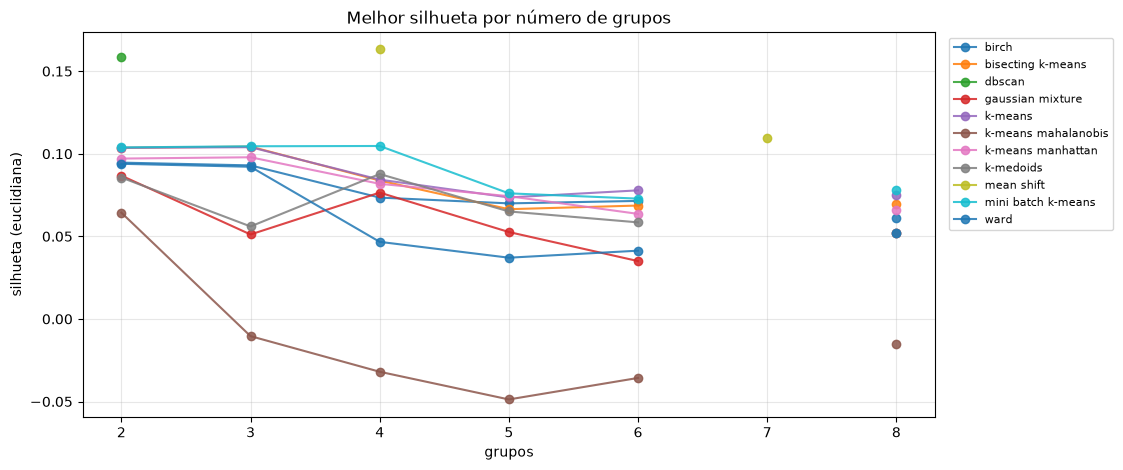

In [8]:
curvas = (
    varredura.query('2 <= grupos <= 10')                  # mean shift e dbscan podem gerar muitos grupos
    .groupby(['grupos', 'modelo'])['silhueta'].max()      # melhor silhueta de cada algoritmo por número de grupos
    .unstack('modelo')
)
ax = curvas.plot(marker='o', figsize=(11, 5), alpha=0.85)
ax.set(title='Melhor silhueta por número de grupos', xlabel='grupos', ylabel='silhueta (euclidiana)')
ax.grid(alpha=0.3)
ax.legend(fontsize=8, bbox_to_anchor=(1.01, 1), loc='upper left')
plt.show()

In [9]:
modelo, params = dict((n, m) for n, m, _ in models)[winner], resumo.loc[winner, 'params']  # vencedor e seus hiperparâmetros
final = clone(modelo).set_params(**params)  # instância nova com a melhor configuração
labels = final.fit_predict(X)               # segmento final de cada imóvel (−1 = ruído, só no dbscan)

print(f'Parâmetros: {params}')
print(f'Silhueta: {resumo.loc[winner, "silhueta"]:.3f}')
print(f'Segmentos: {resumo.loc[winner, "grupos"]}')

Parâmetros: {'batch_size': 256, 'n_clusters': 4}
Silhueta: 0.105
Segmentos: 4


In [10]:
perfil = (
    df.assign(segmento=labels)  # devolve os rótulos à base em unidades de negócio
    .groupby('segmento')
    .agg(
        imoveis=('preco_venda', 'size'),                # tamanho do segmento
        preco_mediano=('preco_venda', 'median'),        # US$
        area_habitavel=('area_habitavel', 'median'),    # pés²
        qualidade_geral=('qualidade_geral', 'median'),  # nota de qualidade
        idade_imovel=('idade_imovel', 'median'),        # anos
    )
    .assign(participacao=lambda d: d['imoveis'] / len(df))  # fatia da carteira
    .sort_values('preco_mediano', ascending=False)
)
perfil.style.format({'preco_mediano': '${:,.0f}', 'area_habitavel': '{:,.0f}', 'participacao': '{:.1%}'})

,imoveis,preco_mediano,area_habitavel,qualidade_geral,idade_imovel,participacao
segmento,,,,,,
2,1092,"$222,500","1,668",7.000000,5.000000,37.3%
3,1078,"$144,000","1,208",5.000000,44.000000,36.8%
0,187,"$136,000","1,320",6.000000,33.000000,6.4%
1,570,"$123,500","1,348",5.000000,83.000000,19.5%


In [11]:
Path('../models').mkdir(exist_ok=True)  # garante a pasta de modelos
modelo_path = Path(f"../models/model_imoveis_{winner.replace(' ', '_').replace('-', '_')}.joblib")
joblib.dump(final, modelo_path)  # salva o modelo ajustado (com os rótulos em labels_)

pd.DataFrame({'segmento': labels}).to_csv('../data/processed/segmentos.csv', sep=';', index=False)  # rótulos para o 05, sem precisar carregar o modelo
Path('../models/selecionado.json').write_text(json.dumps({     # o que o 05 precisa saber do vencedor
    'modelo': winner,
    'params': str(params),
    'grupos': int(resumo.loc[winner, 'grupos']),
    'silhueta': float(resumo.loc[winner, 'silhueta']),
    'arquivo': modelo_path.name,
}, ensure_ascii=False, indent=2))
print(f'Modelo salvo em {modelo_path} · rótulos em segmentos.csv · resumo em selecionado.json')

Modelo salvo em ..\models\model_imoveis_mini_batch_k_means.joblib · rótulos em segmentos.csv · resumo em selecionado.json
